# 实验三 图像拼接

**实验流程**：读取两幅有重叠区域的图像 → SIFT 提取特征 → FLANN 匹配 + Lowe 比率测试 → RANSAC 估计单应矩阵 → 透视变换与拼接。

> 把两张有重叠区域的照片命名为 `a.jpg`、`b.jpg` 放在本 Notebook 同目录下。若没有，代码会自动生成一对示例图，方便先把流程跑通。


In [1]:
import os

import cv2
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams['figure.dpi'] = 110

RESULT_DIR = 'result'
os.makedirs(RESULT_DIR, exist_ok=True)

print('OpenCV:', cv2.__version__)
print('NumPy :', np.__version__)
print('结果目录:', os.path.abspath(RESULT_DIR))


OpenCV: 5.0.0
NumPy : 2.0.1
结果目录: D:\dsh工作区\3rd.exp\result


## 1. 读取图像

若目录下没有 `a.jpg` / `b.jpg`，用 scikit-image 自带的示例图裁出一对有重叠区域的图像，仅用于演示流程。


图像 a 尺寸 (高, 宽, 通道): (221, 191, 3)
图像 b 尺寸 (高, 宽, 通道): (221, 219, 3)


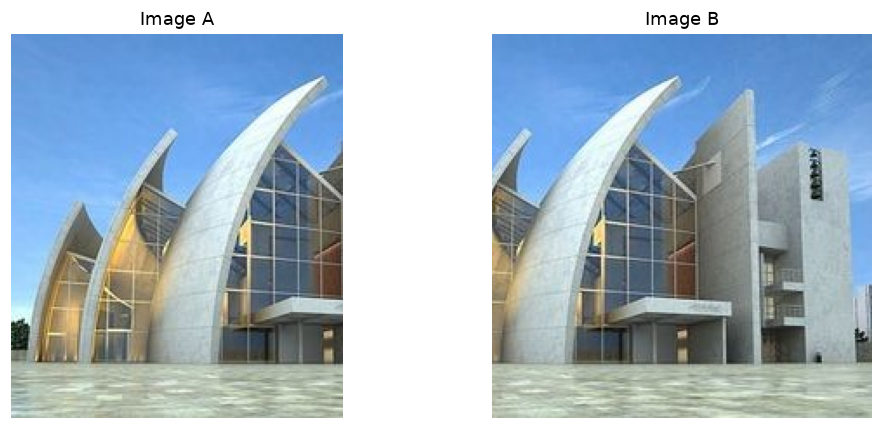

In [2]:
def load_pair():
    """读取 a.jpg / b.jpg；缺失时生成一对有重叠区域的演示图。"""
    if os.path.exists('a.jpg') and os.path.exists('b.jpg'):
        return cv2.imread('a.jpg'), cv2.imread('b.jpg')

    from skimage import data
    base = cv2.cvtColor(data.astronaut(), cv2.COLOR_RGB2BGR)   # 512 x 512
    h, w = base.shape[:2]

    # 左图取左侧 72%，右图取右侧 72%，重叠约 44%
    a = base[:, :int(w * 0.72)].copy()
    b = base[:, int(w * 0.28):].copy()
    cv2.imwrite('a.jpg', a)
    cv2.imwrite('b.jpg', b)
    print('未找到 a.jpg / b.jpg，已生成演示图 a.jpg、b.jpg（正式实验请换成自己的照片）。')
    return a, b


img_a, img_b = load_pair()
assert img_a is not None and img_b is not None, '图像读取失败'
print('图像 a 尺寸 (高, 宽, 通道):', img_a.shape)
print('图像 b 尺寸 (高, 宽, 通道):', img_b.shape)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img_a, cv2.COLOR_BGR2RGB))
plt.title('Image A')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(img_b, cv2.COLOR_BGR2RGB))
plt.title('Image B')
plt.axis('off')
plt.tight_layout()
plt.show()


## 2. SIFT 特征提取

SIFT 对尺度缩放、旋转和亮度变化具有不变性，每个关键点生成 128 维描述子。


In [3]:
gray_a = cv2.cvtColor(img_a, cv2.COLOR_BGR2GRAY)
gray_b = cv2.cvtColor(img_b, cv2.COLOR_BGR2GRAY)

sift = cv2.SIFT_create()
kp_a, des_a = sift.detectAndCompute(gray_a, None)
kp_b, des_b = sift.detectAndCompute(gray_b, None)

print('图像 a 关键点数量:', len(kp_a), ' 描述子形状:', None if des_a is None else des_a.shape)
print('图像 b 关键点数量:', len(kp_b), ' 描述子形状:', None if des_b is None else des_b.shape)


图像 a 关键点数量: 163  描述子形状: (163, 128)
图像 b 关键点数量: 182  描述子形状: (182, 128)


## 3. FLANN 匹配与 Lowe 比率测试

`knnMatch(k=2)` 为每个描述子返回 2 个最近邻；只有当最近邻距离明显小于次近邻（比值 < 0.7）时才认为是可靠匹配。


In [4]:
FLANN_INDEX_KDTREE = 1
index_params = dict(algorithm=FLANN_INDEX_KDTREE, trees=5)
search_params = dict(checks=50)          # 检查次数越多越准，但越慢

flann = cv2.FlannBasedMatcher(index_params, search_params)
matches = flann.knnMatch(des_a, des_b, k=2)

good_matches = []
for m, n in matches:
    if m.distance < 0.7 * n.distance:    # Lowe 比率测试
        good_matches.append(m)

print('原始匹配对数量:', len(matches))
print('比率测试后优质匹配数量:', len(good_matches))


原始匹配对数量: 163
比率测试后优质匹配数量: 62


## 4. RANSAC 估计单应矩阵

用 4 对以上的匹配点求解 3×3 单应矩阵，RANSAC 迭代剔除误匹配，重投影误差阈值取 5 像素。


In [5]:
if len(good_matches) < 4:
    raise RuntimeError('优质匹配点不足 4 对，无法估计单应矩阵，请检查两图是否有足够重叠')

src_pts = np.float32([kp_b[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)
dst_pts = np.float32([kp_a[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)

H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)
inliers = int(mask.sum()) if mask is not None else 0

print('单应矩阵 H =')
print(H)
print(f'RANSAC 内点: {inliers} / {len(good_matches)}  ({inliers / len(good_matches):.1%})')


单应矩阵 H =
[[ 1.00546374e+00  1.99225788e-03  7.27169482e+01]
 [ 8.97625990e-04  1.00409674e+00 -2.39011832e-01]
 [ 1.04648823e-05  1.32288549e-05  1.00000000e+00]]
RANSAC 内点: 60 / 62  (96.8%)


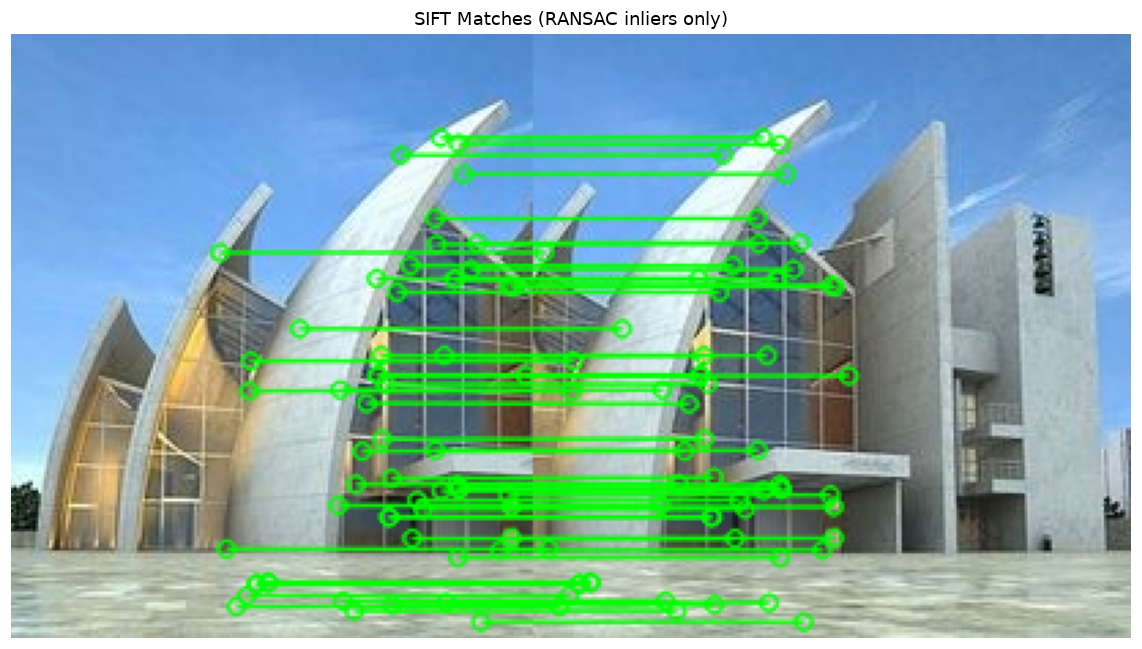

In [6]:
# 内点太多时连线会很乱，这里只画距离最近的 60 条（单应矩阵仍用全部内点估计）
order = np.argsort([m.distance for m in good_matches])
top = order[:60]

vis_matches = [good_matches[i] for i in top]
vis_mask = mask.ravel()[top].astype(int).tolist() if mask is not None else None

draw_params = dict(
    matchColor=(0, 255, 0),
    singlePointColor=(255, 0, 0),
    matchesMask=vis_mask,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS,
)
vis = cv2.drawMatches(img_a, kp_a, img_b, kp_b, vis_matches, None, **draw_params)

plt.figure(figsize=(14, 6))
plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
plt.title('SIFT Matches (RANSAC inliers only)')
plt.axis('off')
plt.tight_layout()
cv2.imwrite(f'{RESULT_DIR}/matches.jpg', vis)
plt.show()


## 5. 透视变换与拼接

把图像 b 变换到图像 a 的坐标系：先计算 b 变换后的四角点，与 a 的角点一起确定画布大小，再用平移矩阵把负坐标挪进画布，最后把 a 贴回对应位置。


In [7]:
h_a, w_a = img_a.shape[:2]
h_b, w_b = img_b.shape[:2]

# b 的四个角点，经 H 变换到 a 的坐标系
pts = np.float32([[0, 0], [0, h_b], [w_b, h_b], [w_b, 0]]).reshape(-1, 1, 2)
dst_corners = cv2.perspectiveTransform(pts, H)

corners_a = np.float32([[0, 0], [w_a, 0], [w_a, h_a], [0, h_a]]).reshape(-1, 1, 2)
all_corners = np.concatenate([dst_corners, corners_a], axis=0)

[x_min, y_min] = np.int32(all_corners.min(axis=0).ravel() - 0.5)
[x_max, y_max] = np.int32(all_corners.max(axis=0).ravel() + 0.5)

# 平移矩阵：保证所有像素坐标非负
translation = np.array([[1, 0, -x_min],
                        [0, 1, -y_min],
                        [0, 0, 1]], dtype=np.float32)

W, Hh = x_max - x_min, y_max - y_min
stitched = cv2.warpPerspective(img_b, translation @ H, (W, Hh))

# 把图像 a 贴回画布（裁剪到画布范围内，避免越界）
x0, y0 = -x_min, -y_min
sx0, sy0 = max(0, x0), max(0, y0)
sx1, sy1 = min(W, x0 + w_a), min(Hh, y0 + h_a)
stitched[sy0:sy1, sx0:sx1] = img_a[sy0 - y0:sy1 - y0, sx0 - x0:sx1 - x0]

print('输出画布尺寸 (宽, 高):', (W, Hh))


输出画布尺寸 (宽, 高): (np.int32(292), np.int32(221))


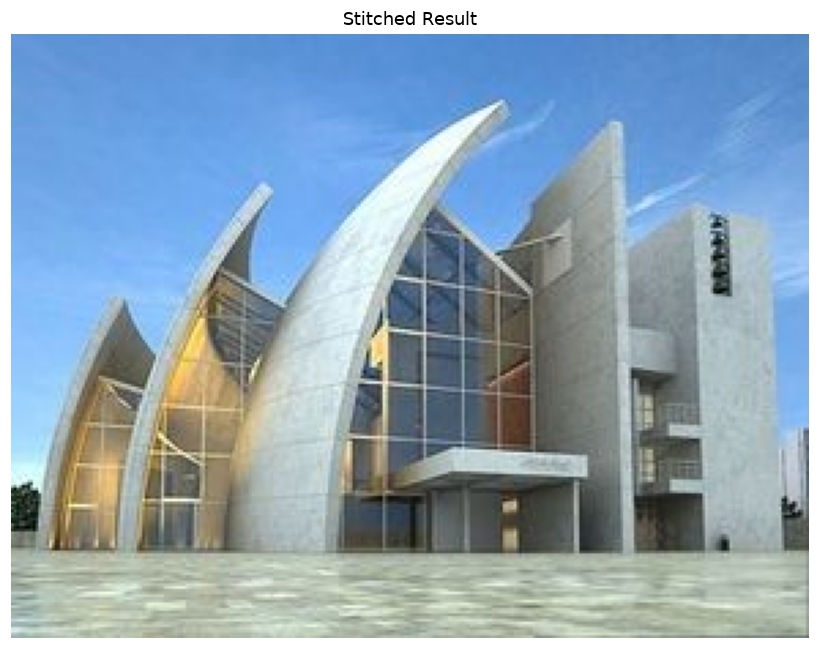

In [8]:
plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(stitched, cv2.COLOR_BGR2RGB))
plt.title('Stitched Result')
plt.axis('off')
plt.tight_layout()
cv2.imwrite(f'{RESULT_DIR}/stitched.jpg', stitched)
plt.show()


## 6. 实验结论

1. **SIFT** 对尺度、旋转、亮度变化具有不变性，是拼接的可靠基础；
2. **Lowe 比率测试**（阈值 0.7）能剔除大量误匹配，显著提高 RANSAC 的稳定性；
3. **RANSAC** 在存在外点的情况下仍能稳健估计单应矩阵，内点比例可反映匹配质量；
4. 简单的"覆盖式"拼接会留下可见接缝，工程中还需图像融合（多频段融合）、曝光补偿等后处理。

完整报告见 [README.md](README.md)。
